# Four-league shots: cleaning, attacking EDA and identity review

This notebook analyzes real Understat data for Premier League, Bundesliga, Serie A and Ligue 1, 2020/21 through a partial September-2025 snapshot of 2025/26. It checks richer retained FBref-category exposure and creates conservative identity proposals. It does not refit the recommendation model or validate transfer success.

Raw source archives, current models and earlier experiments are preserved. Cross-source identities remain provisional, and normalized source rows remain local. Recorded shot-taking players are not a complete appearance/player universe.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import pandas as pd
from IPython.display import display,Image
from src.data.provenance import sha256
folder=ROOT/'reports/four_league_preprocessing'
report=json.loads((folder/'preprocessing.json').read_text())
for path,info in report['outputs'].items():assert sha256(ROOT/path)==info['sha256']
shots=pd.read_parquet(ROOT/'data/processed/real/four_league_clean_shots.parquet')
players=pd.read_parquet(ROOT/'data/processed/real/four_league_player_seasons.parquet')
print({k:report[k] for k in ['shot_events','attempts_excluding_own_goals','own_goal_events','player_seasons','player_club_seasons']})

{'shot_events': 182938, 'attempts_excluding_own_goals': 182300, 'own_goal_events': 638, 'player_seasons': 10087, 'player_club_seasons': 10314}


## 1. Quality and missingness

All required shot IDs, player IDs/names, dates, teams, coordinates and xG are present in the retained extraction. Coordinates and xG are bounded [0,1]; minutes are source match-clock values, including stoppage time. Alternate source home/away fields are reconciled conservatively in the acquisition step, with conflicts tracked rather than guessed.

Own-goal events are retained, but excluded from attempts, goals and summed shooting xG. No missing values are filled with zero. No observations are removed solely because their xG or finishing residual is unusual.

In [2]:
display(pd.read_csv(folder/'quality.csv'))
display(shots[['player','source_player_id','shot_date','team','X','Y','xG','minute']].isna().sum().rename('missing'))
display(shots[['X','Y','xG','minute']].describe())
display(pd.read_csv(folder/'outcomes.csv').groupby('result').events.sum().sort_values(ascending=False))

,league,season,events,valid_events,players,own_goal_events
0,Bundesliga,2020-2021,7590,7590,417,27
1,Bundesliga,2021-2022,7949,7949,414,31
2,Bundesliga,2022-2023,7815,7815,411,23
3,Bundesliga,2023-2024,8506,8506,411,25
4,Bundesliga,2024-2025,7945,7945,409,25
5,Bundesliga,2025-2026,713,713,232,0
6,Ligue 1,2020-2021,8921,8921,471,27
7,Ligue 1,2021-2022,9132,9132,476,34
8,Ligue 1,2022-2023,9345,9345,482,37
9,Ligue 1,2023-2024,7827,7827,444,20


player              0
source_player_id    0
shot_date           0
team                0
X                   0
Y                   0
xG                  0
minute              0
Name: missing, dtype: int64

,X,Y,xG,minute
count,182938.000000,182938.000000,182938.000000,182938.000000
mean,0.851432,0.503824,0.118198,48.791257
std,0.089330,0.122797,0.167327,26.730363
min,0.004000,0.000000,0.000000,0.000000
25%,0.795000,0.418000,0.027138,26.000000
50%,0.869000,0.501000,0.055449,49.000000
75%,0.912000,0.591000,0.102167,71.000000
max,0.999000,0.998000,0.979946,105.000000


result
MissedShots    66733
BlockedShot    49485
SavedShot      42337
Goal           20146
ShotOnPost      3599
OwnGoal          638
Name: events, dtype: int64

## 2. Season coverage and fair descriptive cohorts

All 2025/26 data is partial. Bundesliga 2024/25 is missing one expected match, and Serie A is missing six. Raw/clean tables preserve these cohorts and their coverage flags; comparisons below use completed seasons with the expected match count and at least 20 observed attempts per player.

This support rule is descriptive, not an optimal threshold or a chronological ML validation split. Match-count agreement does not independently guarantee every shot was recorded. There are no verified player-minute denominators here, so **no per-90 shot metrics or appearance counts are fabricated**.

In [3]:
coverage=pd.read_csv(ROOT/'reports/four_league_acquisition/coverage.csv')
display(coverage[coverage.source.eq('understat_worldfootballr')][['league','season','rows','matches','expected_schedule_matches','status']])
cohort=players[~players.partial_season & players.observed_schedule_fraction.eq(1) & players.shots.ge(20)].copy()
assert len(cohort)==report['completed_full_schedule_20_shot_eda_rows']
display(cohort.groupby('league').agg(player_seasons=('source_player_id','size'),median_shots=('shots','median'),median_xg_per_shot=('xg_per_shot','median')))
print('Descriptive cohort rows:',len(cohort))

,league,season,rows,matches,expected_schedule_matches,status
0,Premier League,2020-2021,9235,380.0,380.0,observed_expected_match_count
1,Premier League,2021-2022,9775,380.0,380.0,observed_expected_match_count
2,Premier League,2022-2023,9644,380.0,380.0,observed_expected_match_count
3,Premier League,2023-2024,10524,380.0,380.0,observed_expected_match_count
4,Premier League,2024-2025,9878,380.0,380.0,observed_expected_match_count
5,Premier League,2025-2026,914,40.0,380.0,partial_snapshot
6,Bundesliga,2020-2021,7590,306.0,306.0,observed_expected_match_count
7,Bundesliga,2021-2022,7949,306.0,306.0,observed_expected_match_count
8,Bundesliga,2022-2023,7815,306.0,306.0,observed_expected_match_count
9,Bundesliga,2023-2024,8506,306.0,306.0,observed_expected_match_count


,player_seasons,median_shots,median_xg_per_shot
league,,,
Bundesliga,594,34.0,0.118381
Ligue 1,764,33.0,0.112735
Premier League,854,37.5,0.112977
Serie A,694,35.0,0.106119


Descriptive cohort rows: 2906


## 3. Shot maps, distributions and expected-goals residuals

Map examples are selected by observed non-penalty shot support within the eligible league cohorts, not by future outcomes or market prices. Coordinates are the source's normalized X/Y values, not observed pitch meters; no map depicts a player's physical tracking trajectory.

Goals-minus-xG measures observed over/underperformance against the source's expected-goals estimates. Sample size, chance mix and stochastic conversion affect this residual. A large residual does not establish stable finishing talent. Shots, goals and xG share volume information, so correlations are not independent evidence of predictive ability.

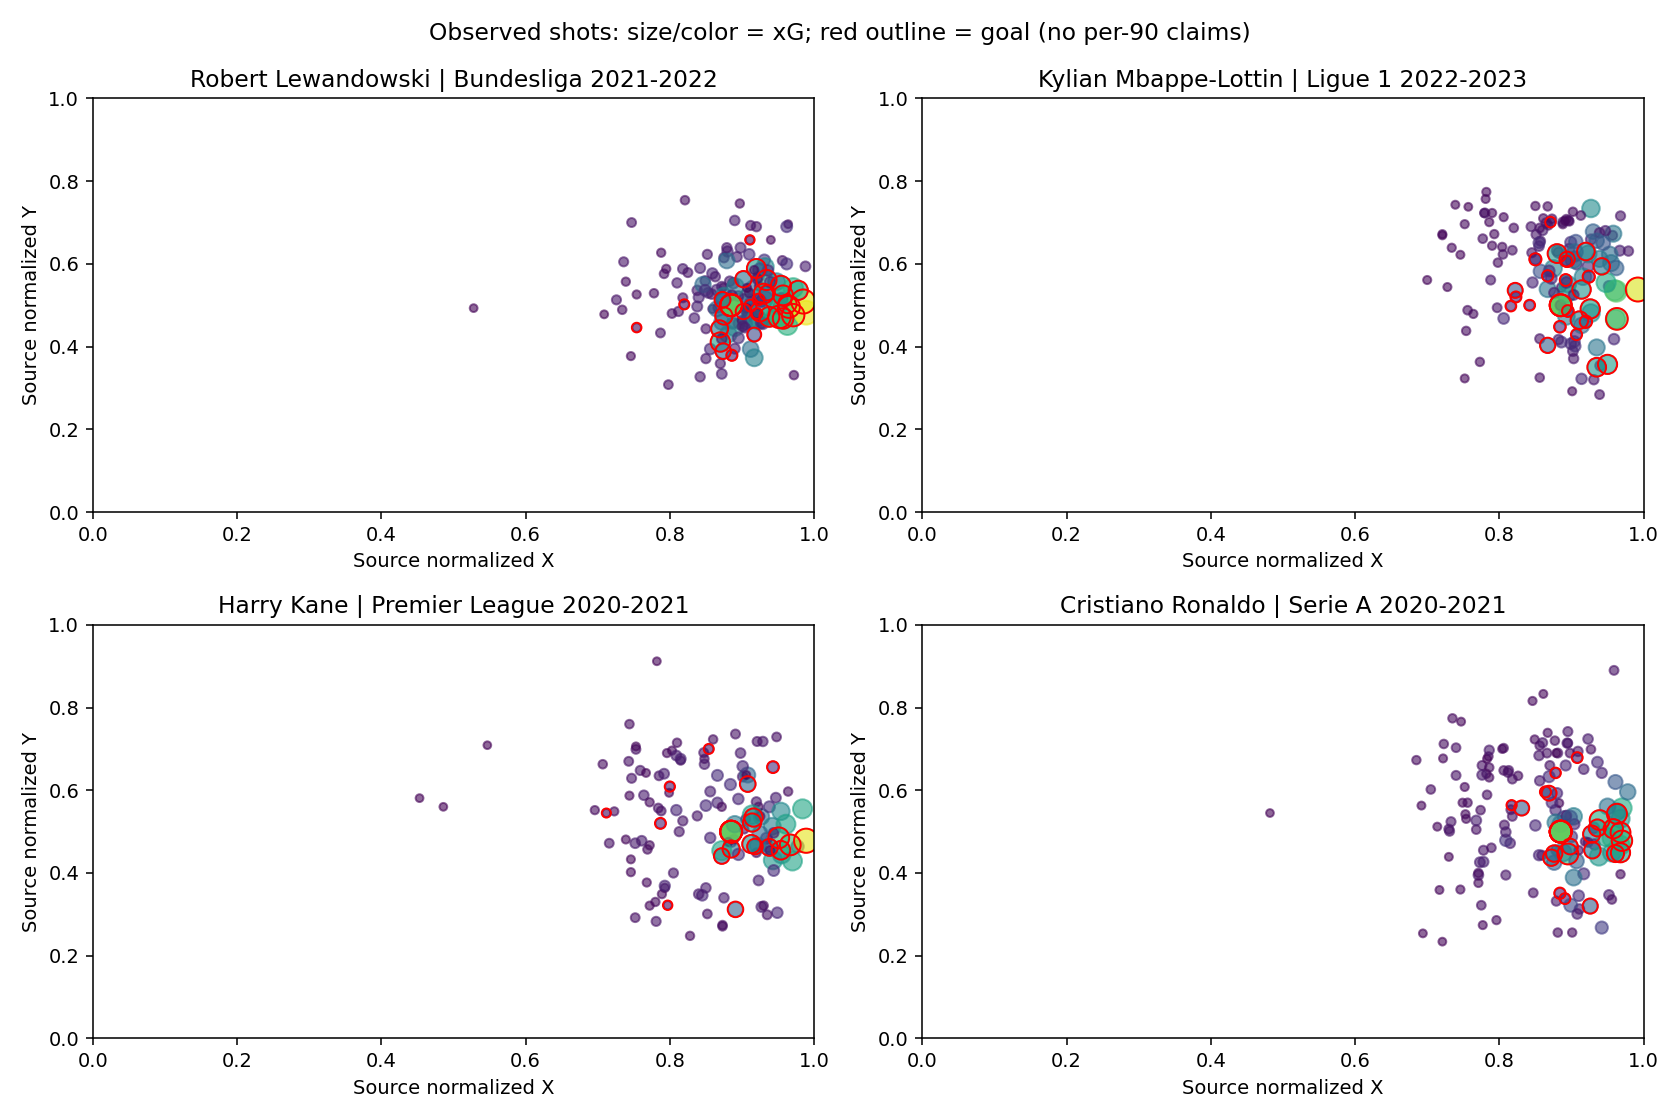

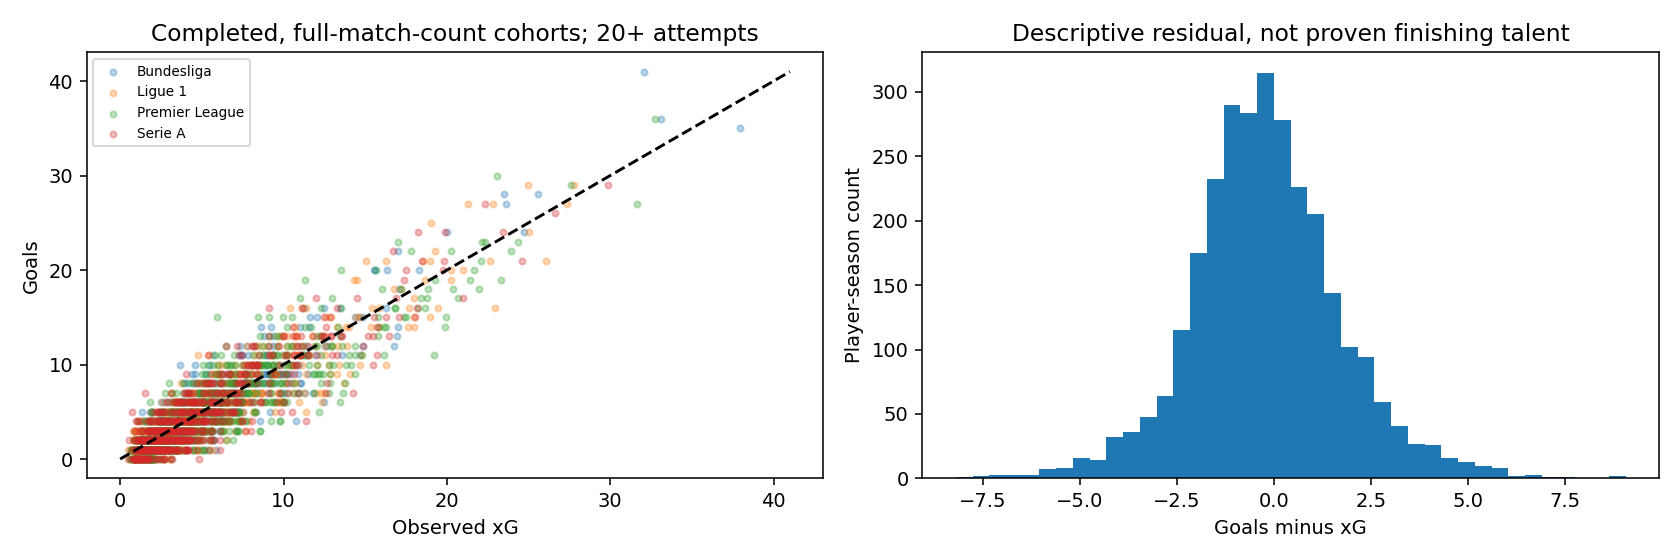

,shots,goals,xg,xg_per_shot,conversion_rate,goals_minus_xg
count,2906.000,2906.000,2906.000,2906.000,2906.000,2906.000
mean,41.530,5.051,5.243,0.118,0.112,-0.192
std,21.206,4.617,4.315,0.052,0.065,1.934
min,20.000,0.000,0.504,0.021,0.000,-8.188
25%,26.000,2.000,2.399,0.079,0.065,-1.336
50%,35.000,4.000,3.974,0.113,0.105,-0.253
75%,51.000,7.000,6.594,0.151,0.154,0.917
max,167.000,41.000,37.924,0.310,0.367,9.050


,shots,goals,xg,xg_per_shot,conversion_rate,goals_minus_xg
shots,1.000,0.809,0.850,0.302,0.293,0.035
goals,0.809,1.000,0.908,0.585,0.729,0.361
xg,0.850,0.908,1.000,0.696,0.537,-0.062
xg_per_shot,0.302,0.585,0.696,1.000,0.686,-0.155
conversion_rate,0.293,0.729,0.537,0.686,1.000,0.541
goals_minus_xg,0.035,0.361,-0.062,-0.155,0.541,1.000


,events
situation,
DirectFreekick,6026
FromCorner,29378
OpenPlay,133923
Penalty,2333
SetPiece,11278


shotType
Head             32129
LeftFoot         58268
OtherBodyPart      852
RightFoot        91689
Name: events, dtype: int64

In [4]:
display(Image(filename=str(folder/'shot_maps.png')))
display(Image(filename=str(folder/'attacking_eda.png')))
display(cohort[['shots','goals','xg','xg_per_shot','conversion_rate','goals_minus_xg']].describe().round(3))
display(pd.read_csv(folder/'correlations.csv',index_col=0).round(3))
display(pd.read_csv(folder/'situations.csv').groupby('situation').agg(events=('events','sum')))
display(pd.read_csv(folder/'shot_types.csv').groupby('shotType').events.sum())

## 4. Season-specific FBref identity proposals

Use the same league, season, conservatively normalized club and exact normalized name. Explicit observed club spellings (for example Manchester United/Manchester Utd and Bayer Leverkusen/Leverkusen) are recorded in `club_aliases.csv`; no fuzzy player matching is used. Reject same-season one-to-many identities. Current/future season observations cannot supply evidence for an earlier season because the matching keys include the season.

These proposals lack independent shared DOB evidence or an approved crosswalk. They are a **review queue**, not canonical merged training records. Name differences, club spelling differences, non-shooters and different source coverage explain some unresolved players. A shot taking-player's identity may be supported in one season but unresolved in another; counts below are player-season observations, not globally unique reviewed people.

In [5]:
identities=pd.read_csv(folder/'identity_coverage.csv')
display(identities)
print('Supported player-season proposals:',int(identities.supported_identity_candidates.sum()))
print('Approved cross-source identities:',report['approved_cross_source_identities'])
assert report['approved_cross_source_identities']==0
review=pd.read_parquet(ROOT/'data/processed/real/four_league_identity_candidates.parquet')
assert review.identity_match_status.eq('provisional_not_reviewed').all()
assert not review.model_use_eligible.any()

,league,season,shot_taking_players,supported_identity_candidates,unresolved_players,approved_identities
0,Bundesliga,2020-2021,417,394,23,0
1,Bundesliga,2021-2022,414,384,30,0
2,Bundesliga,2022-2023,411,380,31,0
3,Bundesliga,2023-2024,411,384,27,0
4,Bundesliga,2024-2025,409,384,25,0
5,Bundesliga,2025-2026,232,213,19,0
6,Ligue 1,2020-2021,471,418,53,0
7,Ligue 1,2021-2022,476,421,55,0
8,Ligue 1,2022-2023,482,431,51,0
9,Ligue 1,2023-2024,444,379,65,0


Supported player-season proposals: 9223
Approved cross-source identities: 0


## 5. Richer FBref features and next integration boundary

The acquired category tables retain passing distances/lengths, key and progressive passing, penalty-area entries, tackle/block zones, touches and take-ons. Exposure compatibility must be checked before deriving per-90 metrics or combining categories. An incompatible category value is retained audit evidence, not a valid complete-season feature.

Avoid filling an unavailable FBref defensive category with Understat shooting values. A combined dashboard should preserve source identities and distinguish confirmed observations, missing categories and provisional cross-source links. Recruitment context and reported valuations remain separately restricted review inputs.

In [6]:
advanced=pd.read_csv(folder/'advanced_feature_eligibility.csv')
display(advanced.groupby(['category','season']).agg(rows=('rows','sum'),compatible_rows=('valid_exposure_rows','sum')))
display(advanced[advanced.valid_exposure_rows.lt(advanced.rows)][['league','season','category','rows','valid_exposure_rows']])
print('Current recommender refitted:',report['current_model_refitted'])
assert not report['current_model_refitted']

rows  compatible_rows
category   season                          
defense    2020-2021  2240           2240.0
           2021-2022  2304           2304.0
           2022-2023  2293           2293.0
           2023-2024  2243           2243.0
           2024-2025  1710            118.0
           2025-2026     0              0.0
misc       2020-2021  2240           2240.0
           2021-2022  2304           2304.0
           2022-2023  2293           2293.0
           2023-2024  2243           2243.0
           2024-2025  1710            118.0
           2025-2026     0              0.0
passing    2020-2021  2240           2240.0
           2021-2022  2304           2304.0
           2022-2023  2293           2293.0
           2023-2024  2243           2243.0
           2024-2025  2253           2253.0
           2025-2026  1558           1557.0
possession 2020-2021  2240           2240.0
           2021-2022  2304           2304.0
           2022-2023  2293           2293.0
           2023-2024  2243           2243.0
           2024-2025  1710            118.0
           2025-2026     0              0.0
shooting   2020-2021  2240           2240.0
           2021-2022  2304           2304.0
           2022-2023  2293           2293.0
           2023-2024  2243           2243.0
           2024-2025  2253           2253.0
           2025-2026  1558           1557.0
standard   2020-2021  2240           2240.0
           2021-2022  2304           2304.0
           2022-2023  2293           2293.0
           2023-2024  2243           2243.0
           2024-2025  2253           2253.0
           2025-2026  1558           1558.0

,league,season,category,rows,valid_exposure_rows
47,Ligue 1,2025-2026,shooting,389,388.0
71,Ligue 1,2025-2026,passing,389,388.0
76,Premier League,2024-2025,defense,439,27.0
82,Bundesliga,2024-2025,defense,379,14.0
88,Serie A,2024-2025,defense,476,39.0
94,Ligue 1,2024-2025,defense,416,38.0
100,Premier League,2024-2025,possession,439,27.0
106,Bundesliga,2024-2025,possession,379,14.0
112,Serie A,2024-2025,possession,476,39.0
118,Ligue 1,2024-2025,possession,416,38.0


Current recommender refitted: False


## Interpretation and decisions

Use these outputs for source-specific shot maps, attacking descriptions and a scoped player-development dashboard. Preserve all partial/incomplete cohorts with explicit flags; exclude them from full-season descriptive comparisons. Show shot support and avoid unsupported per-90 denominators or causal/transfer-success claims. Identity review is the prerequisite for attaching Understat metrics to a FBref recommendation, not a reason to fabricate identifiers or silently relax matching.

Reproduce the data stage with `python -m scripts.four_league_preprocessing` and this notebook with `python -m scripts.four_league_eda_notebook`. Private source tables and identity rows are not redistributed in Git.